In [ ]:
import colorsys
import pickle
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import scipy.sparse as sp
import torch
from matplotlib.collections import LineCollection

DATA_DIR = Path("./figure_partition")

from guts.static_graph.cora_data import induce_train_subgraph, load_cora


def load_partition(name):
    with open(DATA_DIR / name, "rb") as f:
        return pickle.load(f)


def shard_palette(k):
    tiers = [(0.80, 0.55), (0.60, 0.75), (0.45, 0.95)]
    return [matplotlib.colors.to_hex(colorsys.hsv_to_rgb(i / k, *tiers[i % 3])) for i in range(k)]

In [6]:
def plot_partition_network(partition, edge_index, num_nodes, coords_fn, node_size):
    ei = edge_index.numpy()
    A = sp.coo_matrix((np.ones(ei.shape[1]), (ei[0], ei[1])), shape=(num_nodes, num_nodes)).tocsr()
    A = A.maximum(A.T)
    _, labels = sp.csgraph.connected_components(A, directed=False)
    lcc = np.where(labels == np.argmax(np.bincount(labels)))[0]
    print(f"Total nodes: {num_nodes}, LCC nodes: {len(lcc)} ({100.0 * len(lcc) / num_nodes:.1f}%)")

    sub = A[lcc][:, lcc].tocoo()
    G = nx.Graph()
    G.add_nodes_from(range(len(lcc)))
    G.add_edges_from(zip(sub.row.tolist(), sub.col.tolist()))
    G.remove_edges_from(list(nx.selfloop_edges(G)))

    coords = coords_fn(lcc, num_nodes)
    xs, ys = coords[:, 0], coords[:, 1]
    k = len(partition.shards_nodes) or max(partition.node_to_shard.values()) + 1
    colors = shard_palette(k)
    node_colors = [colors[s] if s >= 0 else "#c8c8c8"
                   for s in (partition.node_to_shard.get(int(n), -1) for n in lcc)]

    fig, ax = plt.subplots(figsize=(9.0, 9.0))
    ax.add_collection(LineCollection([((xs[u], ys[u]), (xs[v], ys[v])) for u, v in G.edges()],
                                     colors="#b0b0b0", linewidths=0.3, alpha=0.02, zorder=1))
    ax.scatter(xs, ys, s=node_size * 1.4, c=node_colors, alpha=0.95, linewidths=0, zorder=2)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_aspect("equal")
    ax.autoscale_view()
    plt.show()

Total nodes: 2166, LCC nodes: 1806 (83.4%)


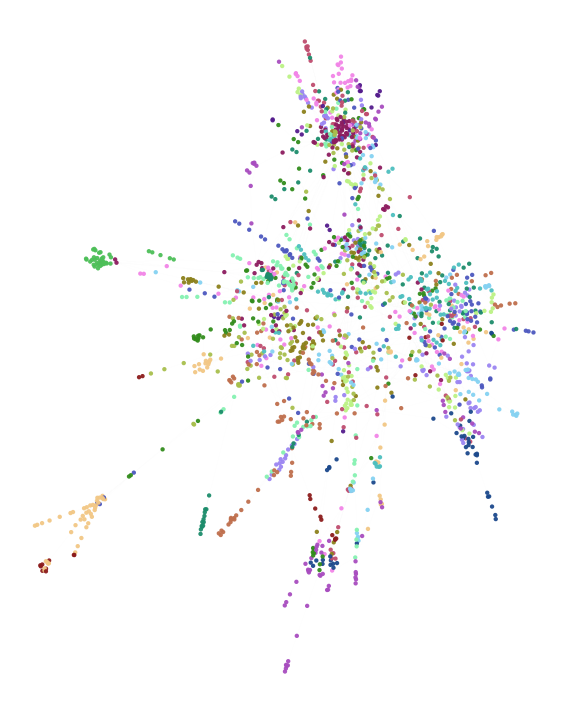

In [7]:
cora_partition = load_partition("cora_partition.pkl")
cora_train, _ = induce_train_subgraph(load_cora(root=str(DATA_DIR), split_seed=42))
cora_layout = np.load(DATA_DIR / "cora_layout.npy")

plot_partition_network(cora_partition, cora_train.edge_index, int(cora_train.x.shape[0]),
                       coords_fn=lambda lcc, n: cora_layout, node_size=7.0)

Total nodes: 40000, LCC nodes: 22878 (57.2%)


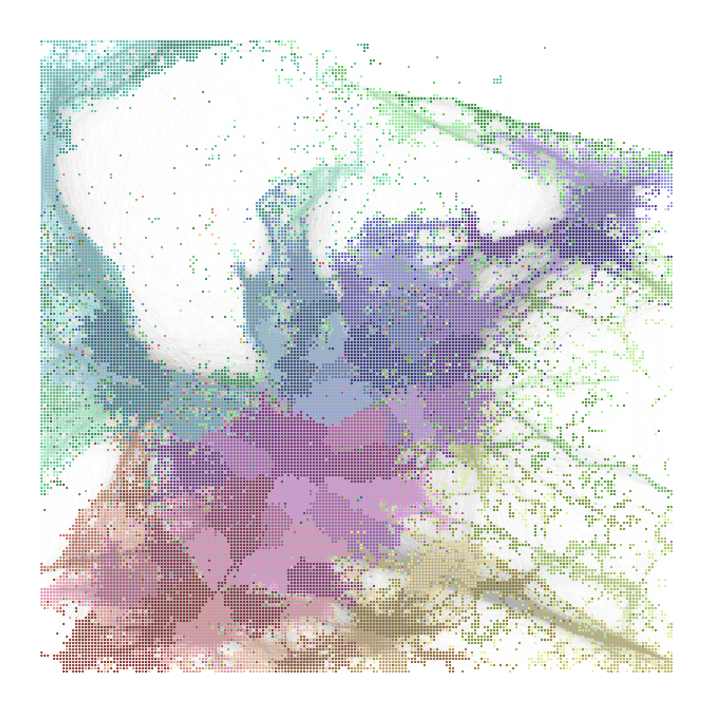

In [8]:
def grid_coords(lcc, num_nodes):
    cols = int(np.ceil(np.sqrt(num_nodes)))
    rows = int(np.ceil(num_nodes / cols))
    row, col = np.divmod(np.arange(num_nodes), cols)
    return np.stack([col + 0.5, (rows - 1 - row) + 0.5], axis=1).astype(np.float64)[lcc]


yjmob_partition = load_partition("yjmob_day0_partition.pkl")
yjmob_graph = torch.load(DATA_DIR / "yjmob_day0_graph.pt", map_location="cpu")

plot_partition_network(yjmob_partition, yjmob_graph["edge_index"].long(), int(yjmob_graph["x"].shape[0]),
                       coords_fn=grid_coords, node_size=2.0)